# El modelo *Integrate and Fire*

## Teoría

El modelo *Integrate and Fire* del comportamiento de una neurona viene descripto por dos ingredientes. En primer lugar, la ODE

\begin{eqnarray}
\frac{dV}{dt}
&=&
f(V(t))
\\
&=&
\frac{1}{\tau}
\left(
E-V(t)
+
RI(t)
\right)
\end{eqnarray}

donde:

* $V(t)$ representa el potencial de membrana al tiempo $t$,

* $E\approx -65mV$ representa el potencial de reposo,

* $\tau\approx 10ms$ representa el tiempo de relajación,

* $R\approx 10M\Omega$ representa una resistencia eléctrica, y

* $I(t)\approx 1nA$ representa una corriente/señal de entrada.

En segundo lugar, un mecanismo de disparo definido por

\begin{eqnarray}
V(t) \to E
\end{eqnarray}

cuando

\begin{eqnarray}
V(t) > V_u
\end{eqnarray}

donde:

* $V_u \approx -50mV$ representa un potencial umbral.

Es decir, según el mecanismo de disparo, el potencial de membrana $V(t)$ se resetea a su valor de reposo $E$ si supera cierto valor umbral $V_u$.

## Unidades

* p = pico = $10^{-12}$
* n = nano = $10^{-9}$
* $\mu$ = micro = $10^{-6}$
* m = mili = $10^{-3}$
* ...
* k = kilo = $10^{3}$
* M = Mega = $10^{6}$
* G = Giga = $10^{9}$
* T = Tera = $10^{12}$

### Ley de Ohm

Si $\Omega$ = Ohmio, V = Voltio y A = Amper, entonces

$$ 1\, Ohm = 1 \Omega = \frac{1 V}{1 A} $$

### Ley RC

Si s = segundos y F = Faradios, entonces

$$ 1 s = 1 \Omega \times 1 F $$

### Hertz

Si Hz = Hertz, luego

$$ 1 Hz = \frac{1}{1 s} $$

### Referencias

* https://technologystudent.com/elec1/ohm1.htm

* https://en.wikipedia.org/wiki/Biological_neuron_model#Leaky_integrate-and-fire

* https://compneuro.neuromatch.io/tutorials/W2D3_BiologicalNeuronModels/student/W2D3_Tutorial1.html



## **Ejercicio 1)** Importando librerías

**1)** Importe las librerías `numpy` para operar con arrays, `scipy` para utilizar rutinas de algebra lineal y `matplotlib.pyplot` para graficar.

**2)** Suba el archivo "libreria" `ode.py` que fabricó en el práctico 4), e impórtelo.

In [3]:
# 1.1)
import numpy as np
import scipy as sp
import scipy.linalg as linalg
import matplotlib.pyplot as plt
import ode

In [2]:
# 1.2)
#import ode

def euler(f,x,t,h,p):
    """
    Calcula un paso de integración del método de Euler.

    Argumentos de entrada:

        f : R^n,R -> R^n
        x = x(t) : R^n
        t = tiempo : R
        h = paso de tiempo : R
        p = parametros : R^q

    Retorna aproximacion numérica de

        x(t+h) : R^n

    según el método de Euler.

    # Ejemplos:
    """
    return x+h*f(x,t,p)

def rk4(f,x,t,h,p):
    """
    Calcula un paso de integración del método de Runge Kutta orden 4.

    Argumentos de entrada:

        f : R^n -> R^n
        x = x(t) : R^n
        t = tiempo : R
        h = paso de tiempo : R
        p = parametros : R^q

    Retorna aproximacion numérica de

        x(t+h) : R^n

    según el método de Runge-Kutta de orden 4.

    # Ejemplos:
    """
    k1 = f(x,t,p)
    k2 = f(x+0.5*h*k1,t+0.5*h,p)
    k3 = f(x+0.5*h*k2,t+0.5*h,p)
    k4 = f(x+h*k3,t+h,p)
    return x+h*(k1+2.0*k2+2.0*k3+k4)/6.0

def integrador_ode(m,f,xa,a,b,k,p,c=lambda x,t,p:x):
    """
    Integra numéricamente la ODE

        dx/dt = f(x,t)

    sobre el intervalo t:[a,b] usando k pasos de integración y el método m, bajo condicion inicial x(a)=x0.
    No es necesario que a<b.

    Argumentos de entrada:

        m = metodo de integracion (ej. euler, rk2, etc.)
        f : R^n -> R^n
        xa = condicion inicial : R
        a = tiempo inicial : R
        b = tiempo final : R
        k = num. pasos de integracion : N
        p = parametros : R^q
        c = función condicionante : R^n,R,p -> R^n

    Retorna:

        t : R^{k+1} , t_j = a+j*h para j=0,1,...,k
        w : R^{n,k+1} , w_ij = x_i(t_j) para i=0,1,...,n-1 y j=0,1,...,k

    donde a+k*dt = b.
    """
    assert k>0
    n = len(xa)
    h = (b-a)/k
    w = np.zeros((n,k+1)) # Produce un array con forma y tipo especificada con los parametros,
                          # lleno de ceros. la forma puede ser espcificada con un entero o tupla (n,k+1)
    t = np.zeros(k+1)
    w[:,0] = xa           # actualiza la posicion inicial (columna de indice 0) de las variables con los valores
                          # de las condiciones iniciales
    t[0] = a              # actualiza la posicion cero con el valor del tiempo inicial

    for j in range(k):    #Aca se produce la iteración en j

        t[j+1] = t[j] + h                # iteracion tiempo
        w[:,j+1] = m(f,w[:,j],t[j],h,p)  # iteracion de w
        w[:,j+1] = c(w[:,j+1],t[j+1],p)  # condicion sobre w

    return t,w

## **Ejercicio 2)** Dinámica con mecanismo de disparo desactivado

En lo que sigue, se considera desactivado el mecanismo de disparo.

**1)** Resuelva analíticamente la ODE del modelo *Integrate and Fire* para una condición inicial arbitraria $V(0)=V_0$ y una corriente de entrada $I=0$.

**2)** Grafique la solución para $V_0=10mV$ y $t\in [0,100]ms$. Incorpore al gráfico una línea punteada indicando el potencial de reposo.

**3)** Realice un análisis geométrico de la solución calculada. Incorpore flechas del campo vectorial así como los puntos fijos estables, inestables y marginales, si los hubiere.

**4)** Repita **1)**, **2)** y **3)** para el caso de corriente de entrada constante, $I=2$nA.

### Extra

**5)** Resuelva analíticamente la ODE para una corriente de entrada $I:t\to I(t)$ arbitraria.

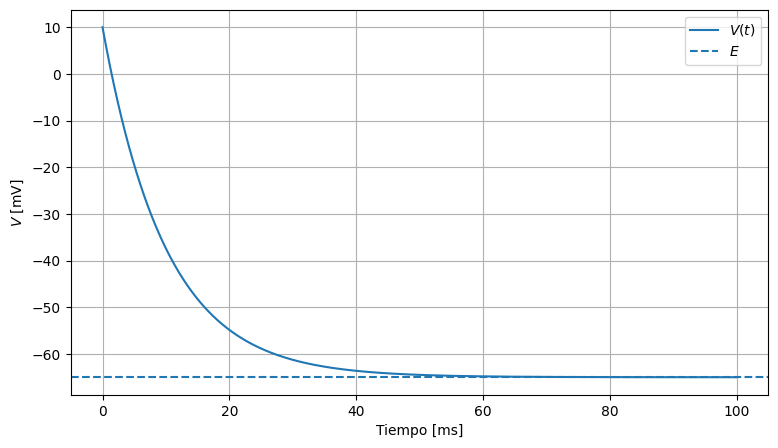

In [4]:
E = -65.0
V0 = 10.0
tau = 10.0

t = np.linspace(0.0,100.0,1001)
V = E + (V0 - E) * np.exp(-t/tau)
plt.figure(figsize=(9,5))
plt.plot(t,V,label=r'$V(t)$')
plt.axhline(E, linestyle ='--', label=r'$E$')
plt.xlabel(r'Tiempo [ms]')
plt.ylabel(r'$V$ [mV]')
plt.grid(True)
plt.legend()
plt.show()


Partimos de la ODE para $I=0$

La ecuación es autónoma porque el lado derecho no depende explícitamente de $t$:

$$f(V) = \frac{E - V}{\tau}$$

Los puntos fijos satisfacen $f(V^*) = 0$. Por lo tanto:

$$V^* = E$$

Para decidir su estabilidad basta observar el signo de $f(V)$:
* Si $V < E$, entonces $E - V > 0$ y $\frac{dV}{dt} > 0$: el potencial aumenta.
* Si $V > E$, entonces $E - V < 0$ y $\frac{dV}{dt} < 0$: el potencial disminuye.

En ambos lados el flujo apunta hacia $V^* = E$, de modo que el punto fijo es **estable**. No aparecen puntos fijos inestables ni marginales.

También puede verificarse mediante la derivada:

$$f'(V) = -\frac{1}{\tau} < 0$$

En un sistema unidimensional, una pendiente negativa de $f$ en el punto fijo indica **estabilidad local**.

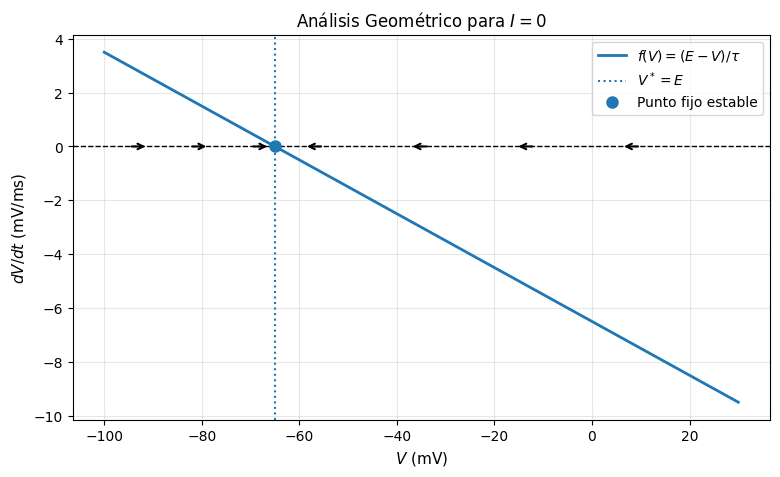

In [6]:

# Parámetros del modelo
E = -65.0  # Potencial de reposo / punto fijo (mV)
tau = 10.0 # Constante de tiempo (ms)

# Rango de V para el gráfico
V_vals = np.linspace(-100, 30, 400)
dVdt = (E - V_vals) / tau

plt.figure(figsize=(9, 5))

# 1. Graficar f(V)
plt.plot(V_vals, dVdt, label=r'$f(V) = (E - V)/\tau$', color='tab:blue', lw=2)
plt.axhline(0, color='black', linestyle='--', linewidth=1)  # Línea horizontal dV/dt = 0
plt.axvline(E, color='tab:blue', linestyle=':', label=r'$V^* = E$') # Línea vertical en punto fijo

# 2. Punto fijo estable
plt.plot(E, 0.0, 'o', color='tab:blue', markersize=8, label='Punto fijo estable')

# 3. Flechas del campo vectorial
# Para V < E (a la izquierda), f(V) > 0 -> flechas hacia la derecha (->)
V_flechas_izq = np.linspace(-95, -70, 3)
for vf in V_flechas_izq:
    plt.annotate('', xy=(vf + 4, 0), xytext=(vf, 0),
                 arrowprops=dict(arrowstyle="->", lw=1.5, color='black'))

# Para V > E (a la derecha), f(V) < 0 -> flechas hacia la izquierda (<-)
V_flechas_der = np.linspace(-55, 10, 4)
for vf in V_flechas_der:
    plt.annotate('', xy=(vf - 4, 0), xytext=(vf, 0),
                 arrowprops=dict(arrowstyle="->", lw=1.5, color='black'))

# Formato de la gráfica
plt.xlabel('$V$ (mV)', fontsize=11)
plt.ylabel('$dV/dt$ (mV/ms)', fontsize=11)
plt.title('Análisis Geométrico para $I = 0$', fontsize=12)
plt.grid(True, alpha=0.3)
plt.legend(loc='upper right')
plt.show()

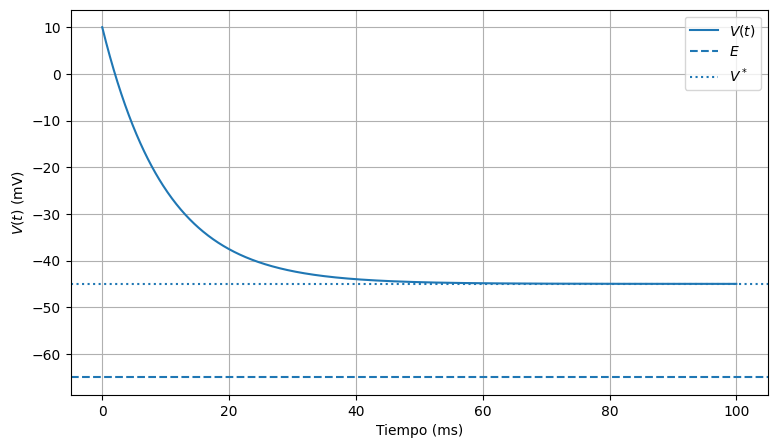

In [9]:
E = -65.0
V0 = 10.0
tau = 10.0
R = 10.0
I0 = 2.0

t = np.linspace(0.0, 100.0, 1001)
V_star = E + R * I0
V = V_star + (V0 - V_star) * np.exp(-t / tau)


plt.figure(figsize=(9, 5))
plt.plot(t, V, label=r'$V(t)$')
plt.axhline(E, linestyle='--', label=r'$E$')
plt.axhline(V_star, linestyle=':', label=r'$V^*$')
plt.xlabel('Tiempo (ms)')
plt.ylabel(r'$V(t)$ (mV)')
plt.grid(True)
plt.legend()
plt.show()

### Análisis geométrico con corriente inyectada ($I_0 > 0$)

La ecuación diferencial autónoma del sistema con corriente constante $I_0$ es:

$$f(V) = \frac{E - V + R \cdot I_0}{\tau}$$

El punto fijo $V^*$ satisface $f(V^*) = 0$:

$$V^* = E + R \cdot I_0$$

Para evaluar la estabilidad observamos el signo del flujo $f(V)$:
* Si $V < V^*$, entonces $f(V) > 0$ y $\frac{dV}{dt} > 0$: el potencial aumenta hacia $V^*$.
* Si $V > V^*$, entonces $f(V) < 0$ y $\frac{dV}{dt} < 0$: el potencial disminuye hacia $V^*$.

La derivada del sistema sigue siendo:

$$f'(V) = -\frac{1}{\tau} < 0$$

Como la pendiente es negativa, el nuevo punto fijo $V^* = -45.0\text{ mV}$ es **asintóticamente estable**. La inyección de corriente $I_0$ desplaza el punto de reposo hacia un potencial más despolarizado.

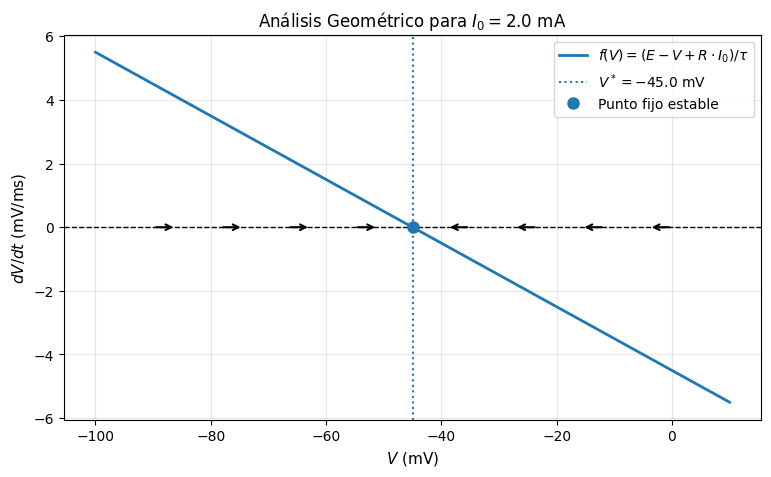

In [10]:
import numpy as np
import matplotlib.pyplot as plt

# Parámetros del problema
E = -65.0
tau = 10.0
R = 10.0
I0 = 2.0

# Punto fijo
V_star = E + R * I0  # -45.0 mV

# Rango de V para graficar f(V) = dV/dt
V_vals = np.linspace(-100, 10, 400)
dVdt = (E - V_vals + R * I0) / tau

plt.figure(figsize=(9, 5))

# 1. Graficar f(V)
plt.plot(V_vals, dVdt, label=r'$f(V) = (E - V + R \cdot I_0)/\tau$', color='tab:blue', lw=2)
plt.axhline(0, color='black', linestyle='--', linewidth=1)
plt.axvline(V_star, color='tab:blue', linestyle=':', label=f'$V^* = {V_star:.1f}$ mV')

# 2. Punto fijo estable
plt.plot(V_star, 0.0, 'o', color='tab:blue', markersize=8, label='Punto fijo estable')

# 3. Flechas del campo vectorial
# V < V*: f(V) > 0 -> flechas hacia la derecha (->)
V_flechas_izq = np.linspace(-90, -55, 4)
for vf in V_flechas_izq:
    plt.annotate('', xy=(vf + 4, 0), xytext=(vf, 0),
                 arrowprops=dict(arrowstyle="->", lw=1.5, color='black'))

# V > V*: f(V) < 0 -> flechas hacia la izquierda (<-)
V_flechas_der = np.linspace(-35, 0, 4)
for vf in V_flechas_der:
    plt.annotate('', xy=(vf - 4, 0), xytext=(vf, 0),
                 arrowprops=dict(arrowstyle="->", lw=1.5, color='black'))

# Formato de la gráfica
plt.xlabel('$V$ (mV)', fontsize=11)
plt.ylabel('$dV/dt$ (mV/ms)', fontsize=11)
plt.title(f'Análisis Geométrico para $I_0 = {I0}$ mA', fontsize=12)
plt.grid(True, alpha=0.3)
plt.legend(loc='upper right')
plt.show()

### Solución analítica para $I(t)$ arbitraria

Partiendo de la ODE lineal de primer orden:

$$\frac{dV(t)}{dt} + \frac{1}{\tau} V(t) = \frac{E + R I(t)}{\tau}$$

Usando el factor integrante $\mu(t) = e^{t/\tau}$:

$$\frac{d}{dt} \left[ V(t) e^{t/\tau} \right] = \frac{E + R I(t)}{\tau} e^{t/\tau}$$

Integrando entre $0$ y $t$ y despejando $V(t)$, obtenemos la **solución general**:

$$V(t) = E + \big(V(0) - E\big)e^{-t/\tau} + \frac{R}{\tau} \int_{0}^{t} e^{-(t - t')/\tau} I(t') \, dt'$$

* **Término homogéneo:** Relajación del estado inicial $V(0)$ hacia el potencial de reposo $E$.
* **Integral de convolución:** Respuesta del sistema ante la corriente de entrada $I(t)$.

## **Ejercicio 3)** Dinámica con mecanismo de disparo activado

**1)** Resuelva numéricamente la ODE del modelo *Integrate and Fire* en el intervalo $t\in [0,200]ms$ para la condición inicial $V(0)=E$ y una corriente de entrada $I(t)=I_0$ para todo $t$ con $I_0=2nA$. Utilice el paso de integración $h=0.05ms$.

**2)** Grafique la solución computada en el inciso **3.1)**. Incorpore al gráfico la solución exacta del inciso **2.1)** (en donde el mecanismo de disparo está desactivado) para la condición inicial del inciso anterior. Además, grafique líneas punteadas horizontales marcando los valores de $V^*$ y $V_u$, donde $V^*$ es el valor de $V$ tal que $f(V)=0$.

**3)** Para el caso indicado en el inciso **3.1)**, calcule analíticamente el período de disparo. Observe si el valor computado corresponde con el observado en el inciso **3.2)**. Grafíque la frencuencia en función de $I_0$.
Que ocurre para valores pequeños de $I_0$?

**4)** Repita **3.1)** y **3.2)** con $I_e(t)=I_0 \cos(t/30ms)$ e $I_0=2.5nA$ para $0\,ms\leq t\leq 500\,ms$. En este caso, no incluya la solución exacta del inciso **2.1)**, pero sí lineas punteadas horizontales para marcar los valores de $E$ y $V_u$.

**5)** Repita **3.1)** y **3.2)** con

\begin{equation}
I(t)= I_0 \, \left(
    \cos{\left( \frac{t}{3ms} \right)} +
    \sin{\left( \frac{t}{5ms} \right)} +
    \cos{\left( \frac{t}{7ms} \right)} +
    \sin{\left( \frac{t}{11ms} \right)} +
    \cos{\left( \frac{t}{13ms} \right)}  \right)^2 \, nA \,
    \;\;\;(4)
\end{equation}

e $I_0=0.35 nA$ para $0\,ms\leq t\leq 200\,ms$. Al igual que en inciso anterior, no incluya la solución exacta del inciso **2.a)**, pero sí lineas punteadas horizontales para marcar los valores de $E$ y $V_u$.

In [25]:
E = -65.0      #mV
V_u = -50.0    #mV
tau = 10.0     #ms
R = 10.0       #MOhm

def rk4_paso(f, V, t, h):
  k1 = f(V, t)
  k2 = f(V + 0.5*h*k1, t + 0.5*h)
  k3 = f(V + 0.5*h*k2, t + 0.5*h)
  k4 = f(V + h*k3, t + h)

  return V + (h/6.0) * (k1 + 2*k2 + 2*k3 + k4)


def integrar_con_disparo(I_fun, V0, t0, tf, h):
    npasos = int(round((tf - t0) / h))
    tiempos = t0 + h * np.arange(npasos + 1)
    V = np.zeros(npasos + 1)
    V[0] = V0
    disparos = []

    def f(v, t):
      return (E - v + R * I_fun(t)) / tau


    for n in range(npasos):
      V_siguiente = rk4_paso(f, V[n], tiempos[n], h)

      if V_siguiente >= V_u:
          disparos.append(tiempos[n+1])
          V[n+1] = E
      else:
          V[n+1] = V_siguiente

    return tiempos, V, np.array(disparos)

In [26]:
I0 = 2.0
I_constante = lambda t: I0

V0 = E
t, V_num, t_disparos = integrar_con_disparo(
                        I_constante, V0, 0.0, 200.0, 0.05)

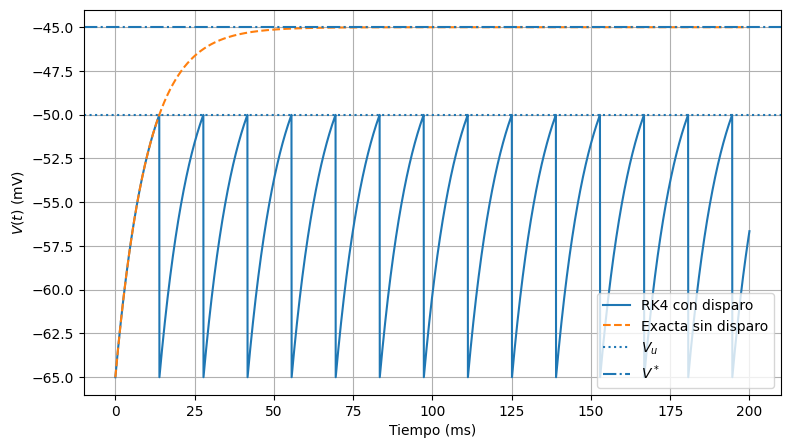

In [27]:
V_star = E + R * I0
V_exacta = E + R * I0 * (1.0 - np.exp(-t / tau))


plt.figure(figsize=(9, 5))
plt.plot(t, V_num, label='RK4 con disparo')
plt.plot(t, V_exacta, linestyle='--', label='Exacta sin disparo')
plt.axhline(V_u, linestyle=':', label=r'$V_u$')
plt.axhline(V_star, linestyle='-.', label=r'$V^*$')
plt.xlabel('Tiempo (ms)')
plt.ylabel(r'$V(t)$ (mV)')
plt.grid(True)
plt.legend()
plt.show()

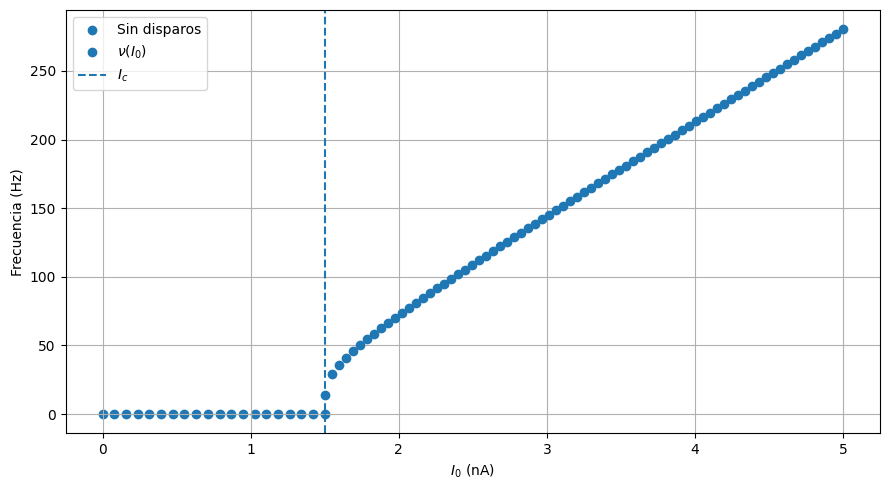

In [28]:
#Frecuencia en funcion de I0
I_c = (V_u - E) / R

# Zona sin disparos: I0 <= Ic
I_sin_disparo = np.linspace(0.0, I_c, 20)
frecuencia_cero = np.zeros_like(I_sin_disparo)

# Zona con disparos: I0 > Ic
I_vals = np.linspace(I_c + 1e-3, 5.0, 75)
T_vals = -tau * np.log(
1.0 - (V_u - E) / (R * I_vals)
)
frecuencia_vals = 1000.0 / T_vals

plt.figure(figsize=(9, 5))

# Frecuencia cero para corrientes subumbrales
plt.scatter(I_sin_disparo, frecuencia_cero, label='Sin disparos', color='tab:blue')


# Curva de frecuencia para corrientes supraumbrales
plt.plot(
I_vals,
frecuencia_vals,
'o',
label=r'$\nu(I_0)$'
)

plt.axvline(
I_c,
linestyle='--',
label=r'$I_c$'
)

plt.xlabel(r'$I_0$ (nA)')
plt.ylabel('Frecuencia (Hz)')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

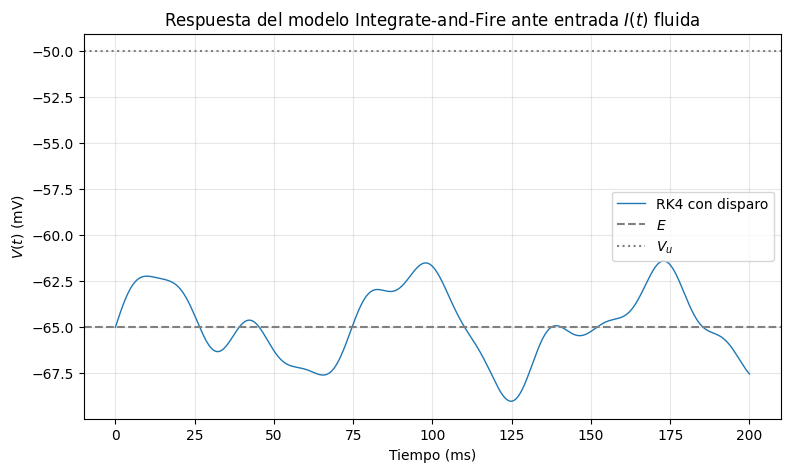

In [29]:

# Parámetros del modelo
E = -65.0      # mV
V_u = -50.0    # mV
I0 = 0.35      # nA (o 2.5 si tu guía lo requiere)

# Definición de la función I(t) dada por la Ecuación (4)
def I_compleja(t):
    suma_trig = (
        np.cos(t / 3.0) +
        np.sin(t / 5.0) +
        np.cos(t / 7.0) +
        np.sin(t / 11.0) +
        np.cos(t / 13.0)
    )
    return (I0 / 2.0) * suma_trig

# Integración con disparo de t=0 a t=200 ms
t_comp, V_comp, disparos_comp = integrar_con_disparo(
    I_compleja, E, 0.0, 200.0, 0.05
)

# Gráfico
plt.figure(figsize=(9, 5))
plt.plot(t_comp, V_comp, label='RK4 con disparo', lw=1)
plt.axhline(E, linestyle='--', color='gray', label=r'$E$')
plt.axhline(V_u, linestyle=':', color='gray', label=r'$V_u$')

plt.xlabel('Tiempo (ms)')
plt.ylabel(r'$V(t)$ (mV)')
plt.title('Respuesta del modelo Integrate-and-Fire ante entrada $I(t)$ fluida')
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

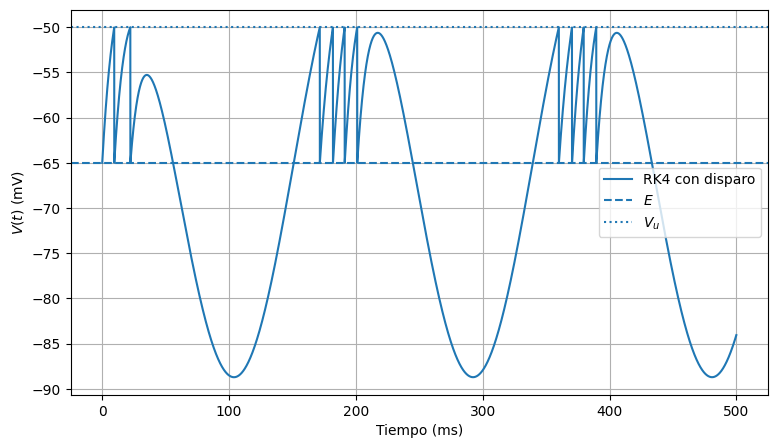

In [31]:

I0 = 2.5

def I_cos(t):
  return I0 * np.cos(t / 30.0)


t_cos, V_cos, disparos_cos = integrar_con_disparo(
I_cos, E, 0.0, 500.0, 0.05
)
plt.figure(figsize=(9, 5))
plt.plot(t_cos, V_cos, label='RK4 con disparo')
plt.axhline(E, linestyle='--', label=r'$E$')
plt.axhline(V_u, linestyle=':', label=r'$V_u$')
plt.xlabel('Tiempo (ms)')
plt.ylabel(r'$V(t)$ (mV)')
plt.grid(True)
plt.legend()
plt.show()